> **練習用ノート** — 各説明の直後にある空のコードセルへ、自分で実装してください。
> 正解例は `diffusion1.ipynb` にあります。

# Diffusion Model の実装練習: 2 次元三日月データ

このノートブックでは、二次元の三日月型データ `x_0 in R^2` に対して DDPM の学習を実装します。

流れは次の通りです。

1. 数式で、順方向過程とノイズ予測学習を確認する
2. 二次元三日月データを作る
3. 空のコードセルに、ノイズを足す処理と学習ステップを自分で実装する
4. 学習後、ノイズから三日月データを生成する


注意：場面によって時刻の作り方が違う

| 場面 | 時刻` t` |
|---|---|
| 学習 | サンプルごとにランダム |
| 特定時刻の可視化 | 全サンプルで同じ時刻 |
| 逆拡散による生成 | T-1,T-2,...,0 と順番に戻る |

## 0. ライブラリの準備

ここは練習対象ではありません。そのまま実行してください。
必要なライブラリ、乱数シード、計算デバイスを一度だけ設定します。

### 直後のコードセルで行うこと

ここは実装練習ではありません。ライブラリの読み込み、乱数シードの固定、計算デバイスの選択を行います。そのまま実行し、`device` が `cpu` または `cuda` になったことを確認します。

### このセルで使う主な名前

- モジュール: `math`, `random`, `matplotlib.pyplot`, `torch`, `torch.nn`, `torch.nn.functional`
- 外部関数: `sklearn.datasets.make_moons`
- 設定で使う関数: `random.seed`, `torch.manual_seed`, `torch.device`, `torch.cuda.is_available`


In [1]:
import math
import random

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import make_moons as sklearn_make_moons

seed = 0
random.seed(seed)
torch.manual_seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cpu')

## 1. 実装問題: 二次元三日月データ

`scikit-learn` の `sklearn.datasets.make_moons` を使って三日月型データを作り、PyTorch のテンソルへ変換してください。三日月を数式から手作りする必要はありません。

### 1.1 `make_moons`

この直後のセルでは `make_moons` だけを書きます。

- 役割: scikit-learnで三日月座標を作り、PyTorch Tensorとして返す
- 推奨値: `n_samples=1000`, `data_jitter=0.06`
- 使用する関数: `sklearn_make_moons`, `torch.tensor`
- 出力shape: `[n_samples, 2]`

`data_jitter` は、三日月データを作る時点で輪郭を少しばらつかせる値です。これはDDPMが後から加えるノイズ $\epsilon$ とは別物です。scikit-learn側の引数名は変更できないため、呼び出しでは `noise=data_jitter` と対応づけます。

このノートでは座標の中心化や標準化は行いません。`make_moons` が作る元データの理論平均はおおよそ `E[x0] = [0.5, 0.25]` です。`data_jitter` は平均0なので、有限サンプルでは少しずれても理論平均は変わりません。

描画はこの関数に入れず、別のセルで扱います。


In [2]:
def make_moons(n_samples=1000, data_jitter=0.06, device=device):
    x_numpy, _ = sklearn_make_moons(n_samples=n_samples, noise=data_jitter, random_state=0)
    x0 = torch.tensor(x_numpy, dtype=torch.float32, device=device)
    return x0


### 1.2 `plot_points`

このセルでは `plot_points` だけを書きます。`[n_samples, 2]` のTensorを散布図にして `ax` を返します。

単独の図にも後の複数パネルにも使えるように、`ax=None` なら新しい図を作り、`ax` が渡されたらその場所へ描く設計にします。推奨値は `s=6`, `opacity=0.7` です。

- 入力: `x`, `title=None`, `ax=None`, `s=6`, `opacity=0.7`
- 使用する関数: `plt.subplots`, `ax.scatter`, `detach`, `cpu`
- 出力: 描画に使った `ax`


In [3]:
def plot_points(x, title=None, ax=None, s=6, opacity=0.7):
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 4))

    x_cpu = x.detach().cpu()
    ax.scatter(x_cpu[:, 0], x_cpu[:, 1], s=s, alpha=opacity)
    ax.set_aspect("equal")
    if title is not None:
        ax.set_title(title)
    return ax


### 1.3 データ生成と表示

関数は定義しません。`make_moons` と `plot_points` を呼びます。動作確認・標準ともに1000点です。

このデータは中心化していないため、理論平均は `E[x0] = [0.5, 0.25]` です。ここでいうサンプルは三日月を構成する点1個を指します。


<Axes: >

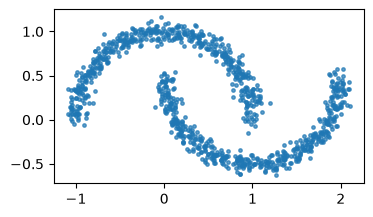

In [4]:
x0 = make_moons(1000)
plot_points(x0)

## 2. ノイズスケジュールを決める

### この節でやること

ここでは、**各時刻でどれくらいノイズを加えるかという予定表**を作ります。
まだデータにはノイズを加えません。

順拡散では、元データを一度に壊すのではなく、$T$ 回に分けて少しずつ壊します。

$$
x_0 \rightarrow x_1 \rightarrow x_2 \rightarrow \cdots \rightarrow x_T
$$

各時刻 $t$ で加えるノイズの強さを $\beta_t$ とします。

- $\beta_t$ が小さい: そのステップで加えるノイズは少ない
- $\beta_t$ が大きい: そのステップで加えるノイズは多い

このノートでは $T=100$ とし、$\beta_t$ を $0.0001$ から $0.04$ まで少しずつ大きくします。最初は慎重に、後半ほど強く壊す設定です。

### この節の出力

この節で用意するのは、長さ $T$ の表 `beta` だけです。

- `beta[t]`: 時刻 $t$ で新しく加えるノイズの強さ

### 直後のコードセルで実装すること

このコードセルでは、ノイズを加える前に `beta` を作ります。

1. 総時刻数 `T` を決める
2. 小さいノイズ量から大きいノイズ量まで、長さ `T` の一次元Tensor `beta` を作る

この段階では、まだ `x0` にノイズを加えません。

### このセルで使う主な関数名

- 等間隔の値を作る: `torch.linspace`

この節では新しい自作関数を定義せず、`beta` という一次元Tensorだけを作ります。



In [5]:
T=100
beta = torch.linspace(1e-4, 0.04, T, device=device)

### 2.1 ノイズ量 `beta` を曲線で確認する

直前に作った `beta` を曲線で表示し、各ステップで新しく加えるノイズ量が時刻とともに増えていることを確認します。

### 直後のコードセルで行うこと

作成した `beta` を、横軸を時刻 `t`、縦軸をそのステップのノイズ量として描きます。最初は小さく、時刻が進むにつれて大きくなることを確認します。このセルでは新しい自作関数を定義しません。

### このセルで使う主な関数名

- 時刻軸を作る: `torch.arange`
- TensorをCPUへ移す: `detach`, `cpu`
- 曲線を描く: `plt.subplots`, `ax.plot`, `plt.show`

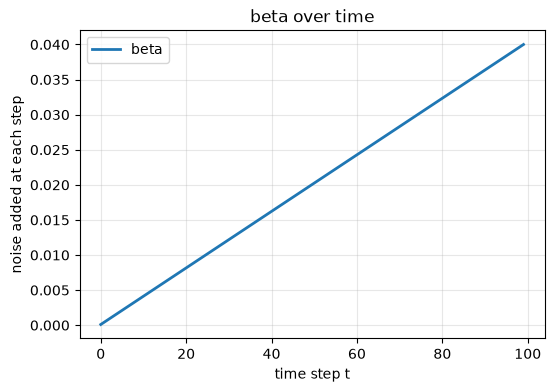

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))

time_steps = torch.arange(T)
ax.plot(time_steps, beta.detach().cpu(), linewidth=2, label="beta")

ax.set_xlabel("time step t")
ax.set_ylabel("noise added at each step")
ax.set_title("beta over time")
ax.grid(alpha=0.3)
ax.legend()

plt.show()

## 3. 順拡散の式を順番に作る

### この節のゴール

ノイズスケジュール $\beta_t$ から、元データ $x_0$ を任意の時刻の $x_t$ へ直接変換する式

$$
x_t
=
\sqrt{\prod_{s=1}^{t}(1-\beta_s)}\,x_0
+
\sqrt{1-\prod_{s=1}^{t}(1-\beta_s)}\,\epsilon
$$

を得るのが、この節のゴールです。以下では、この式が出てくるまでを順番に追います。

### 1. まず、1ステップだけノイズを加える

時刻 $t-1$ のデータから時刻 $t$ のデータを、次のように作ると決めます。

$$
x_t
=
\sqrt{1-\beta_t}\,x_{t-1}
+
\sqrt{\beta_t}\,\epsilon_t,
\qquad
\epsilon_t\sim\mathcal N(0,I)
$$

右辺は二つの部分に分かれています。

- $\sqrt{1-\beta_t}\,x_{t-1}$: 少し弱めた元信号
- $\sqrt{\beta_t}\,\epsilon_t$: 今回新しく加えるガウスノイズ

ここは正規分布から自動的に出てくる式ではなく、**DDPMが採用するデータの壊し方**です。

### 2. この式の平均を求める

ある一つの $x_{t-1}$ を固定し、ノイズ $\epsilon_t$ だけを何度も変えると考えます。
ガウスノイズの平均は0です。

$$
\mathbb E[\epsilon_t]=0
$$

したがって、

$$
\begin{aligned}
\mathbb E[x_t\mid x_{t-1}]
&=
\sqrt{1-\beta_t}\,x_{t-1}
+
\sqrt{\beta_t}\,\mathbb E[\epsilon_t]\\
&=
\sqrt{1-\beta_t}\,x_{t-1}
\end{aligned}
$$

となります。

つまり、同じ $x_{t-1}$ に異なるノイズを何度も加えて得られる点群の中心は、

$$
\sqrt{1-\beta_t}\,x_{t-1}
$$

です。期待値は理論上は無限回試したときの平均ですが、実際にその平均を計算してから学習するわけではありません。

### 3. この式の分散を求める

$x_{t-1}$ を固定しているので、ばらつきを作るのはノイズ部分だけです。
確率変数を $a$ 倍すると、分散は $a^2$ 倍になります。

$$
\operatorname{Var}(aX)=a^2\operatorname{Var}(X)
$$

$\operatorname{Var}(\epsilon_t)=I$ なので、

$$
\begin{aligned}
\operatorname{Var}(x_t\mid x_{t-1})
&=
\operatorname{Var}(\sqrt{\beta_t}\,\epsilon_t)\\
&=
(\sqrt{\beta_t})^2I\\
&=
\beta_t I
\end{aligned}
$$

となります。

以上から、1ステップ後の分布は

$$
q(x_t\mid x_{t-1})
=
\mathcal N\left(
\sqrt{1-\beta_t}\,x_{t-1},
\beta_t I
\right)
$$

です。ここで $q$ は、**決められた順拡散の確率分布につけた名前**です。

### 4. なぜ係数に平方根を使うのか

$x_{t-1}$ と $\epsilon_t$ の分散がどちらも1で、互いに独立だとします。
このとき、信号部分が全体の分散へ寄与する量は

$$
(\sqrt{1-\beta_t})^2=1-\beta_t
$$

で、ノイズ部分が寄与する量は

$$
(\sqrt{\beta_t})^2=\beta_t
$$

です。二つを足すと、

$$
\underbrace{(1-\beta_t)}_{\text{信号由来の分散}}
+
\underbrace{\beta_t}_{\text{ノイズ由来の分散}}
=1
$$

となります。値そのものを足しているのではなく、**二つの独立な部分が全体の分散へ寄与する量**を足しています。
これにより、全体のスケールを大きく変えず、信号の一部をノイズへ置き換えられます。

### 5. 何ステップも繰り返すと、信号の係数は積になる

1ステップごとに、信号には $\sqrt{1-\beta_s}$ が掛かります。
したがって、$x_0$ から時刻 $t$ までに信号へ掛かる係数は、

$$
\begin{aligned}
&\sqrt{1-\beta_1}
\sqrt{1-\beta_2}
\cdots
\sqrt{1-\beta_t}\\
&=\sqrt{\prod_{s=1}^{t}(1-\beta_s)}
\end{aligned}
$$

です。平方根の中身

$$
\prod_{s=1}^{t}(1-\beta_s)
$$

この積を、ここで `beta_keep[t]` と呼ぶことにします。つまり `beta_keep[t]` は、時刻 $t$ まで残っている信号の割合です。

### 6. 時刻 $t$ までに蓄積したノイズの分散を求める

$x_0$ を固定したときの $x_t$ の分散を $v_t$ とします。
1ステップ進むと、それまでの分散は $1-\beta_t$ 倍され、新しいノイズの分散 $\beta_t$ が加わります。

$$
v_t=(1-\beta_t)v_{t-1}+\beta_t,
\qquad v_0=0
$$

ここで $u_t=1-v_t$ と置くと、

$$
\begin{aligned}
u_t
&=1-v_t\\
&=1-\{(1-\beta_t)v_{t-1}+\beta_t\}\\
&=(1-\beta_t)(1-v_{t-1})\\
&=(1-\beta_t)u_{t-1}
\end{aligned}
$$

です。$u_0=1$ なので、

$$
u_t
=(1-\beta_t)(1-\beta_{t-1})\cdots(1-\beta_1)
=\prod_{s=1}^{t}(1-\beta_s)
$$

となります。$u_t=1-v_t$ を戻すと、

$$
v_t
=1-\prod_{s=1}^{t}(1-\beta_s)
$$

です。

つまり、

- $\prod_{s=1}^{t}(1-\beta_s)$: 残っている信号の割合
- $1-\prod_{s=1}^{t}(1-\beta_s)$: 蓄積したノイズの割合

という関係です。

### 7. $x_0$ から $x_t$ を直接作る

ここまでで、時刻 $t$ の平均と分散が分かりました。

$$
q(x_t\mid x_0)
=
\mathcal N\left(
\sqrt{\prod_{s=1}^{t}(1-\beta_s)}\,x_0,
\left(1-\prod_{s=1}^{t}(1-\beta_s)\right)I
\right)
$$

したがって、標準正規ノイズ $\epsilon\sim\mathcal N(0,I)$ を一度生成すれば、

$$
x_t
=
\sqrt{\prod_{s=1}^{t}(1-\beta_s)}\,x_0
+
\sqrt{1-\prod_{s=1}^{t}(1-\beta_s)}\,\epsilon
$$

として、$x_1,x_2,\ldots,x_{t-1}$ を順番に計算せず、$x_0$ から任意の $x_t$ を直接作れます。

### この節の流れ

```text
1ステップの壊し方を決める
        ↓
その平均と分散を求める
        ↓
何ステップも繰り返した信号の係数を求める
        ↓
その積に beta_keep という名前を付ける
        ↓
蓄積したノイズの分散を求める
        ↓
x₀から任意のxₜを直接作る式を得る
```

### 3.1 `beta_keep` を作って曲線で確認する

ここまでの1〜7は、`x_0` から `x_t` を直接作る式がなぜ成り立つかを説明する導出です。直後のコードセルで実装するのは、その途中で現れた積を、すべての時刻について一度に計算する部分です。

数式では

$$
\text{beta\_keep}[t]=\prod_{s=1}^{t}(1-\beta_s)
$$

で、コードでは `torch.cumprod(1 - beta, dim=0)` に対応します。

```text
beta.shape      = [T]  各ステップで新しく加えるノイズ量
beta_keep.shape = [T]  各時刻までに残っている信号の割合
```

1. `1 - beta` で、各ステップで信号を残す割合を作る
2. `torch.cumprod(..., dim=0)` で、先頭から各時刻までの積を求める
3. `beta_keep` を曲線にし、時刻とともに信号が減ることを確認する

この `beta_keep` は、次の `extract_timestep_values` と `q_sample` で、各サンプル（三日月の点）の時刻に対応する係数を取り出すために使います。

- 累積積を求める: `torch.cumprod`
- 時刻軸を作る: `torch.arange`
- 曲線を描く: `plt.subplots`, `ax.plot`, `plt.show`


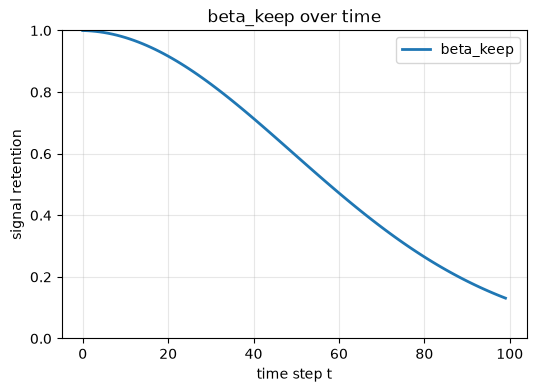

In [7]:
beta_keep = torch.cumprod(1 - beta, dim=0)

fig, ax = plt.subplots(figsize=(6, 4))

time_steps = torch.arange(T)
ax.plot(time_steps, beta_keep.detach().cpu(), linewidth=2, label="beta_keep")

ax.set_xlabel("time step t")
ax.set_ylabel("signal retention")
ax.set_title("beta_keep over time")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

plt.show()


### 3.2 `extract_timestep_values`

この直後のセルでは `extract_timestep_values` だけを書きます。

役割は、**長さ `T` の時刻表 `values` から、バッチ内の各サンプル（三日月の点）に指定された時刻の値を取り出すこと**です。三日月のデータ点やノイズそのものを取り出す関数ではありません。

例えば `values=beta_keep`、`t=[3, 72, 18, 45]` なら、次の4個を取り出します。

```text
[beta_keep[3], beta_keep[72], beta_keep[18], beta_keep[45]]
```

ここで `t` は、バッチ内の各サンプル（三日月の点）が持つ時刻番号です。

```text
values.shape = [T]
t.shape      = [batch]
t.dtype      = torch.long
```

学習時の `t` は連続した時刻列ではなく、例えば `[3, 72, 18, 45]` のようにサンプル（三日月の点）ごとにランダムです。ここで `batch` は時間の長さではなく、同時に処理するデータ数です。

`values[t]` でサンプル（三日月の点）ごとの係数を取り出すとshapeは `[batch]` になります。これを `[batch, 1]` に変形して返し、各点のx座標とy座標へ同じ係数を掛けられるようにします。

`extract_timestep_values` はPythonの整数1個ではなく、必ず `t=[batch]` の1次元Tensorを受け取る設計にします。なお、コードの `t=0` は数式上の最初のノイズステップに対応します。

- 関数名の意味: `extract`（取り出す）+ `timestep_values`（指定時刻の値）
- 入力: `values=[T]`, `t=[batch]`
- 出力: `[batch, 1]`
- このノートでの使用例: `values=beta_keep` または `values=beta`
- 使用する操作: Tensorのインデックス参照、`unsqueeze`


In [8]:
def extract_timestep_values(values: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
    assert t.dtype == torch.long, (
        f"tはtorch.longが必要です: dtype={t.dtype}"
    )
    assert t.ndim == 1, (
        f"tは[batch]の1次元Tensorが必要です: shape={tuple(t.shape)}"
    )
    return values[t].unsqueeze(1)

In [ ]:
t = torch.full(
    (x0.shape[0],),
    50,
    dtype=torch.long,
    device=x0.device,
)

beta_keep_t = extract_timestep_values(beta_keep, t)
# beta_keep_t.shape
beta_keep_t

### 3.3 `q_sample`

この直後のセルでは `q_sample` だけを書きます。

`q_sample` 自体は時刻をランダムに選びません。呼び出し元から、各サンプル（三日月の点）の時刻 `t=[batch]` を受け取ります。

1. `torch.randn_like(x0)` で、各サンプル（三日月の点）・各座標に独立した拡散ノイズ `epsilon` を作る
2. `extract_timestep_values(beta_keep, t)` で各サンプル（三日月の点）の信号保持率を取り出す
3. `[batch, 1]` の係数を `expand_as(x0)` で `[batch, 2]` に明示的に広げる
4. 順拡散の式へ代入して `xt` を作る
5. `xt` と、生の標準正規ノイズ `epsilon` を返す

```text
x0.shape       = [batch, 2]
t.shape        = [batch]
beta_keep.shape = [T]
beta_keep_t    = [batch, 1]
signal_scale   = [batch, 2]
epsilon_scale  = [batch, 2]
xt.shape       = [batch, 2]
epsilon.shape = [batch, 2]
```

`epsilon` はDDPMの数式にある $\epsilon\sim\mathcal N(0,I)$ です。`make_moons` の `data_jitter` とは異なり、`q_sample` を呼ぶたびに新しく生成され、後の学習ではモデルが予測する正解になります。実際に `x0` へ加わる成分は、生の `epsilon` ではなく `epsilon_scale * epsilon` です。

- 使用する関数: `torch.randn_like`, `torch.sqrt`, `extract_timestep_values`


In [10]:
def q_sample(x0, t, beta_keep):
    epsilon = torch.randn_like(x0)

    # [batch, 1]
    beta_keep_t = extract_timestep_values(beta_keep, t)

    # [batch, 1] -> [batch, 2]
    signal_scale = torch.sqrt(beta_keep_t).expand_as(x0)
    epsilon_scale = torch.sqrt(1 - beta_keep_t).expand_as(x0)

    # すべて[batch, 2]なので、掛け算が分かりやすい
    scaled_epsilon = epsilon_scale * epsilon
    xt = signal_scale * x0 + scaled_epsilon
    return xt, epsilon

In [11]:
t= torch.full((x0.shape[0],), 20, dtype=torch.long,)
xt, epsilon = q_sample(x0=x0, t=t, beta_keep=beta_keep)
xt.shape, epsilon.shape

(torch.Size([1000, 2]), torch.Size([1000, 2]))

### 3.4 順拡散を図で確認する

`q_sample` が正しく書けると、時刻が大きいほど三日月の形が崩れていきます。

### 直後のコードセルで実装すること

このコードセルでは、直前に作った `q_sample` の動作を図で確認します。

**このノートで表示する時刻は `[0, 24, 49, 74, 99]` の5個に固定します。** `T=100` なので、有効な時刻番号は `0` から `99` までです。

- `t=0`: ほぼ元データ
- `t=24`: 約25%進んだ状態
- `t=49`: 約50%進んだ状態
- `t=74`: 約75%進んだ状態
- `t=99`: 最終時刻に近い状態

1. 表示用の三日月データを作る
2. ループ制御用のPythonリスト `ts = [0, 24, 49, 74, 99]` を作る
3. 各時刻について、バッチ内の全サンプル（三日月の点）に同じ時刻を割り当てる
4. `q_sample` で `xt` を作る
5. 1段目に `xt`、2段目に生の `epsilon`、3段目に実際に加わる `scaled_epsilon` を表示する

時刻が進むほど三日月の形が崩れ、ガウスノイズに近づけば順拡散は期待どおりです。

### このセルで使う主な関数名

- 表示する時刻を作る: Pythonのリスト
- バッチ全体へ同じ時刻を割り当てる: `torch.full`
- 順拡散を実行する: `q_sample`
- 複数の図を作る: `plt.subplots`
- 点群を描く: `plot_points`
- レイアウトを整える: `plt.tight_layout`
- 図を表示する: `plt.show`

この可視化では、例えば `t=49` の図なら、`torch.full` で `[49, 49, ..., 49]` のような `t_batch` を作り、全サンプル（三日月の点）へ同じ時刻を割り当てます。

生の `epsilon` はどの時刻でも標準正規分布なので、見た目の広がりはほぼ同じです。時刻とともに大きくなるのは `sqrt(1 - beta_keep_t)` で重み付けした `scaled_epsilon` のほうです。

中心化していないため、理論平均は `E[x0] = [0.5, 0.25]` です。したがって `E[x99] = sqrt(beta_keep[99]) E[x0] ≈ 0.361964 [0.5, 0.25] ≈ [0.1810, 0.0905]` です。有限個の点から計算した平均は、この値の近くで少し揺れます。


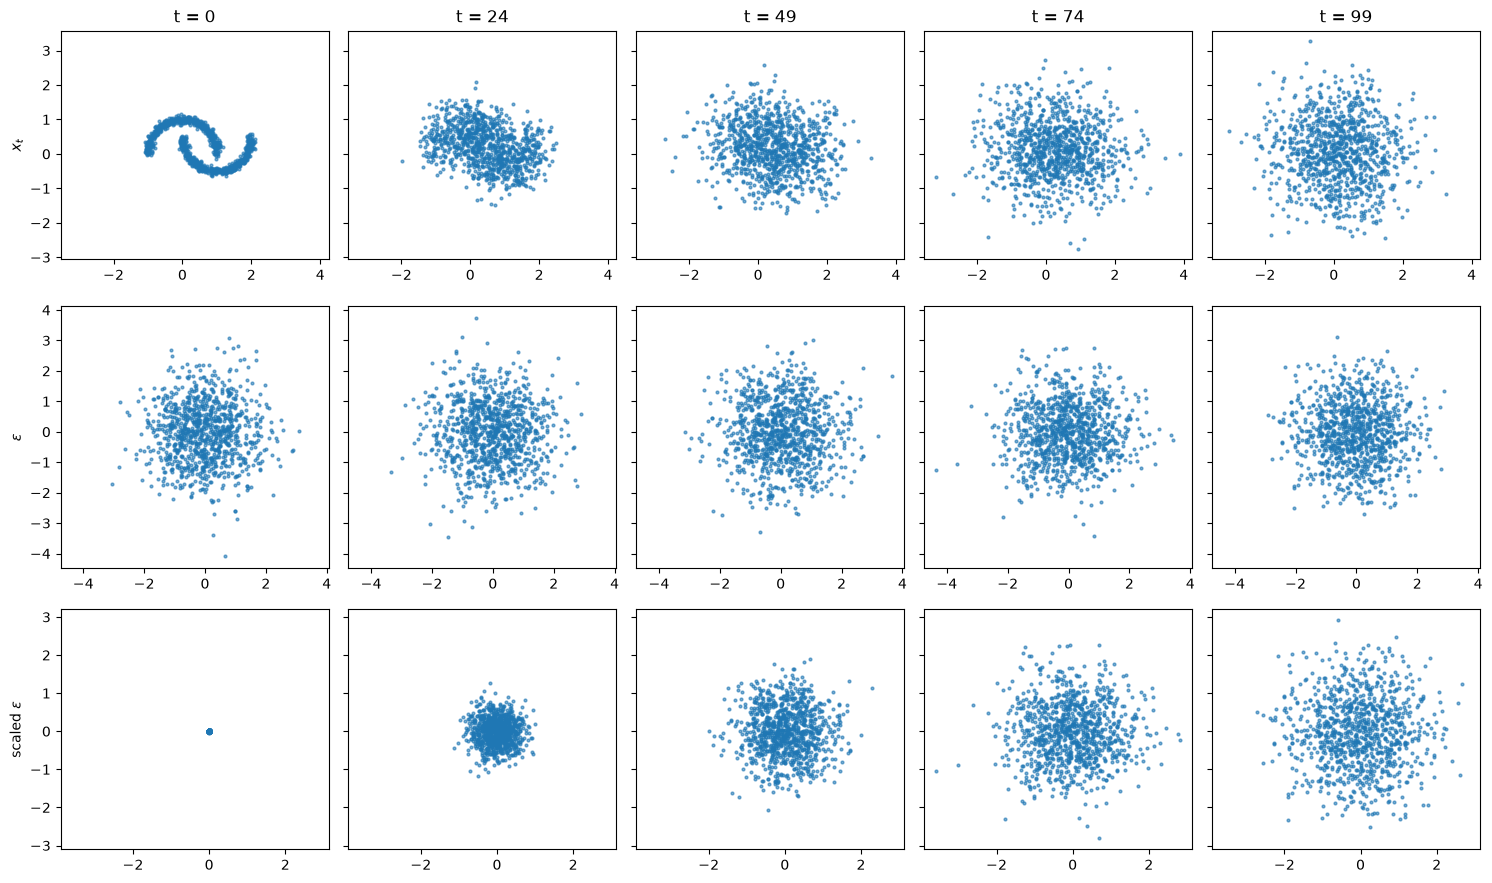

In [12]:
ts = [0, 24, 49, 74, 99]

fig, axes = plt.subplots(3, len(ts), figsize=(15, 9), sharex="row", sharey="row")

for column, t_value in enumerate(ts):
    # 例：t=49なら[49, 49, ..., 49]を作る
    t_batch = torch.full((x0.shape[0], ), t_value, dtype=torch.long, device=x0.device)
    xt, epsilon = q_sample(x0, t_batch, beta_keep)
    beta_keep_t = extract_timestep_values(beta_keep, t_batch)
    epsilon_scale = torch.sqrt(1 - beta_keep_t).expand_as(x0)
    scaled_epsilon = epsilon_scale * epsilon

    plot_points(xt, f"t = {t_value}", ax=axes[0, column], s=4, opacity=0.6)
    plot_points(epsilon, ax=axes[1, column], s=4, opacity=0.6)
    plot_points(scaled_epsilon, ax=axes[2, column], s=4, opacity=0.6)

axes[0, 0].set_ylabel("$x_t$")
axes[1, 0].set_ylabel("$\\epsilon$")
axes[2, 0].set_ylabel("scaled $\\epsilon$")
plt.tight_layout()
plt.show()


## 4. GELUとReLUの違い

このノートのMLPでは、Transformerで見慣れている `GELU` を使います。ここでは実装問題や比較グラフにはせず、`ReLU` との違いだけを言葉で確認します。

### ReLU

`ReLU` は、入力が負なら出力を0にし、入力が正ならそのまま通します。つまり「負なら切る、正なら通す」という硬い門のような処理です。計算が単純な一方、負側の情報と勾配は0になり、0の位置で折れ曲がります。

### GELU

`GELU` は、入力を0かそのままかに急に分けず、入力の大きさに応じて滑らかに通す量を変えます。小さな負の入力も少し残り、0付近にもReLUのような角がありません。

要するに、`ReLU` は入力を硬く選別し、`GELU` は入力を滑らかに重み付けします。今回 `GELU` を使うのはモデル設計上の選択であり、DDPMの数式から決まるものではありません。

> 補足: Diffusion系のモデルでは、滑らかな活性化関数である `SiLU` もよく使われます。このノートでは、Transformerで見慣れている `GELU` を使います。

次の `DenoiseMLP` では、隠れ層の活性化関数として `nn.GELU()` を使います。


## 5. モデル

モデルは `x_t` と時刻 `t` を受け取り、足されたノイズ `epsilon` を予測します。

時刻 `t` を sinusoidal embedding に変換し、`x_t` とともに MLP に入力するモデルを自分で実装します。

### 5.1 `sinusoidal_embedding`

この直後のセルでは `sinusoidal_embedding` だけを書きます。

#### 16本針のアナログ時計として考える

このノートでは `dim=32` の時間埋め込みを作ります。1本の針の位置をsinとcosの2個で表すため、最初から**回転速度の違う針が16本ある時計**だと考えます。

```text
dim=32
1本の針につき2個の値（sinとcos）
num_freqs = 32 // 2 = 16本
```

`num_freqs` は、周波数、つまり針の回転速度が何種類あるかを表します。

```text
時刻 t                 : 16本の針をどこまで進めるか
freqs[i]               : i番目の針が回る速さ
sin(t × freqs[i])      : i番目の針の縦位置
cos(t × freqs[i])      : i番目の針の横位置
```

各針についてsinだけでは縦位置しか分かりません。例えば30度と150度はどちらも `sin=0.5` です。cosも使えば横位置が異なるため、針の位置を区別できます。

針が1本だけだと、一周後に同じ位置へ戻ります。そこで、速く回る針からゆっくり回る針まで16本を使い、**16本すべての位置の組合せ**を時刻の特徴にします。速い針は短い時間差で大きく変わり、遅い針は長い範囲でゆっくり変わります。

コードでは、まず16本分のsinを並べ、その後ろに16本分のcosを並べます。

```text
[sin_0, sin_1, ..., sin_15, cos_0, cos_1, ..., cos_15]
```

これで1個の時刻 `t` が32個の数になります。16本はDDPMの必須条件ではなく、このノートで `dim=32` と決めた結果です。

#### Tensorのshapeとの対応

Tensorのshapeは次の順で変わります。

```text
t                    : [batch]
t.unsqueeze(1)       : [batch, 1]
freqs               : [num_freqs]
freqs.unsqueeze(0)   : [1, num_freqs]
args                 : [batch, num_freqs]
sin(args)            : [batch, num_freqs]
cos(args)            : [batch, num_freqs]
cat([sin, cos])      : [batch, dim]
```

- 役割: 整数時刻 `t` をsin・cosからなる時刻ベクトルへ変換する
- 推奨値: `dim=32`
- 入力shape: `t=[batch]`
- 出力shape: `[batch, dim]`
- 使用する関数: `torch.arange`, `torch.exp`, `torch.sin`, `torch.cos`, `torch.cat`

このセルでは時刻ベクトルの作成だけを扱い、MLP本体は別のセルで扱います。


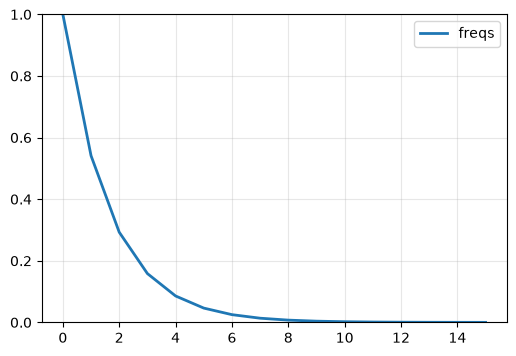

In [13]:
freqs = torch.logspace(0, -4, steps=16, device=t.device)
fig, ax = plt.subplots(figsize=(6, 4))

freq_index = torch.arange(16)
ax.plot(freq_index, freqs.detach().cpu(), linewidth=2, label="freqs")

ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

plt.show()

In [14]:
# from torch import Tensor


def sinusoidal_embedding(
    t: torch.Tensor,
    dim: int=32
) -> torch.Tensor:
    
    num_freqs = dim // 2
    freqs = torch.logspace(0, -4, steps=num_freqs, device=t.device)
    # print(f"{freqs=}")

    # [batch, 1] * [1, num_freqs] -> [batch, num_freqs]
    args = t.float().unsqueeze(1) * freqs.unsqueeze(0)
    emb = torch.cat([torch.sin(args), torch.cos(args)], dim=1)

    return emb # [batch, dim]

emb = sinusoidal_embedding(t=torch.tensor([75], dtype=torch.long), dim=32)
print(f"{emb=}")



emb=tensor([[-0.3878,  0.2503,  0.0263, -0.6285,  0.1490, -0.3331,  0.9514,  0.8519,
          0.5242,  0.2942,  0.1609,  0.0873,  0.0473,  0.0256,  0.0139,  0.0075,
          0.9218, -0.9682, -0.9997,  0.7778,  0.9888, -0.9429, -0.3080,  0.5238,
          0.8516,  0.9558,  0.9870,  0.9962,  0.9989,  0.9997,  0.9999,  1.0000]])


### 5.2 時間埋め込みを可視化する

このセルは穴埋め問題ではなく、5.1で作った時間埋め込みの動きを確認するための可視化です。

左のヒートマップでは、横軸が埋め込みの32次元、縦軸が時刻 `t=0,...,99`、色が各sin・cos成分の値です。

```text
0〜15列  : 16種類の周波数のsin成分
16〜31列 : 同じ16種類の周波数のcos成分
```

縞が細かい列ほど速く回る時計、ゆっくり色が変わる列ほど遅く回る時計です。

右のグラフでは、sin側から `[0, 4, 8, 15]` 列を選びます。低い列番号は速く振動し、高い列番号はゆっくり変化することを確認します。

この可視化が実行できれば、`sinusoidal_embedding` の出力shapeは `[T, 32]` です。MLPの作成はまだ行いません。

- 時刻を並べる: `torch.arange`
- 埋め込みを作る: `sinusoidal_embedding`
- ヒートマップを描く: `ax.imshow`
- 曲線を描く: `ax.plot`


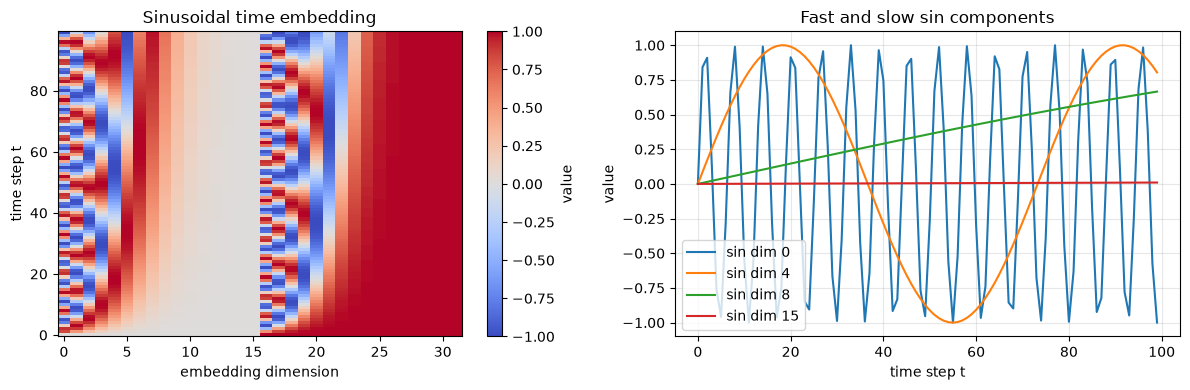

In [15]:
time_dim_vis = 32 # 時刻を32次元で表現するよ。
t_vis = torch.arange(T, device=device, dtype=torch.long) # ステップ数 T=100で t=0,...,99となる
embedding_vis = sinusoidal_embedding(t_vis, dim=time_dim_vis).detach().cpu()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

### Sinusoidal time embedding ###

image = axes[0].imshow(
    embedding_vis,
    aspect="auto",
    origin="lower",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
axes[0].set_xlabel("embedding dimension")
axes[0].set_ylabel("time step t")
axes[0].set_title("Sinusoidal time embedding")
fig.colorbar(image, ax=axes[0], label="value")

### Fast and slow sin components ###

selected_sin_dims = [0, 4, 8, 15]
for dim_index in selected_sin_dims:
    axes[1].plot(
        t_vis.detach().cpu(),
        embedding_vis[:, dim_index],
        label=f"sin dim {dim_index}",
    )
axes[1].set_xlabel("time step t")
axes[1].set_ylabel("value")
axes[1].set_title("Fast and slow sin components")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


### 5.3 `DenoiseMLP`

このセルでは `DenoiseMLP` クラスだけを書きます。`forward(x, t)` は `[batch, 2]` の予測ノイズを返します。

今回は隠れ層の活性化関数に `nn.GELU()` を使います。Transformerで使うGELUと同じPyTorchのモジュールです。GELUを使うこと自体はモデル設計上の選択で、DDPMの必須条件ではありません。

- 入力: `x=[batch, 2]`, `t=[batch]`
- 出力: 予測したノイズ `[batch, 2]`
- 主な部品: `nn.Linear`, `nn.GELU`, `nn.Sequential`, `torch.cat`
- 推奨値: `hidden_dim=128`、`time_dim=32`

x   : [batch, 2]

t_emb : [batch, 32]

 ↓ dim=1で列を連結

h   : [batch, 34]


In [16]:
class DenoiseMLP(nn.Module):
    def __init__(self, time_dim=32, hidden_dim=128):
        super().__init__() # 親クラスnn.Moduleの初期化

        # xの次元は今回2次元
        self.net = nn.Sequential(
            nn.Linear(2 + time_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, 2),
        )
        self.time_dim = time_dim

    def forward(self, x, t):
        t_emb = sinusoidal_embedding(t, self.time_dim)
        h = torch.cat([x, t_emb], dim=1)
        return self.net(h)

### 5.4 モデル生成

関数は定義しません。`DenoiseMLP(time_dim=32, hidden_dim=128)` を作り、`device` へ移します。


In [17]:
model = DenoiseMLP(time_dim=32, hidden_dim=128).to(device)

## 6. 実装問題: 学習ステップ

各ステップでは、次を行います。

1. データ $x_0$ を用意する
2. 各サンプル（三日月の点）にランダムな時刻 $t$ を選ぶ
3. $x_t$ と実際のノイズ $\epsilon$ を作る
4. モデルにノイズを予測させる
5. MSE で学習する

DDPM の基本的な学習では、ニューラルネットワーク `epsilon_theta(x_t, t)` に、足されたノイズ `epsilon` を予測させます。

$$
\mathcal{L}(\theta) =
\mathbb{E}_{x_0, t, \epsilon}
\left[
  \|\epsilon - \epsilon_\theta(x_t, t)\|_2^2
\right]
$$

今回のデータは二次元なので、`x_t` も `epsilon` も `shape = [batch, 2]` です。モデルは「ノイズが混ざった点」と「時刻 `t`」を受け取り、二次元ノイズを返します。

### 期待値は「何を変えながら平均するのか」

このノートには、似て見える二種類の期待値が出てきます。

#### 1. $\mathbb{E}[x_t\mid x_{t-1}]$ の意味

縦線 $\mid$ は「右側を固定した条件で」という意味です。

$$
\mathbb{E}[x_t\mid x_{t-1}]
$$

は、**ある一つの $x_{t-1}$ を固定し、加えるノイズ $\epsilon_t$ だけを何度も変えて $x_t$ を作ったときの平均**です。

例えば、同じ点 $x_{t-1}$ に対して異なるガウスノイズを1万回加えると、1万個の $x_t$ ができます。それらを座標ごとに平均したものが、この条件付き期待値です。ノイズは正方向と負方向に同じように出るため平均すると0になり、

$$
\mathbb{E}[x_t\mid x_{t-1}]
=\sqrt{1-\beta_t}\,x_{t-1}
$$

だけが残ります。

#### 2. 損失の $\mathbb{E}_{x_0,t,\epsilon}$ の意味

$$
\mathcal{L}(\theta)
=
\mathbb{E}_{x_0,t,\epsilon}
\left[
\|\epsilon-\epsilon_\theta(x_t,t)\|_2^2
\right]
$$

下付きの $x_0,t,\epsilon$ は、**この三つを毎回変えながら、角括弧の中の誤差を平均する**という意味です。

それぞれは次の場所から選ばれます。

- $x_0$: 学習データから選んだ、ノイズを加える前の元データ
- $t$: ノイズを加える時刻。通常は $0$ から $T-1$ までからランダムに選ぶ
- $\epsilon$: そのデータに実際に加える、標準正規分布から生成したランダムノイズ

数式を日本語の手順に直すと、次の意味です。

1. 学習データから元データ $x_0$ を選ぶ
2. 時刻 $t$ をランダムに選ぶ
3. ノイズ $\epsilon$ をランダムに生成する
4. $x_0,t,\epsilon$ から、ノイズが加わった $x_t$ を作る
5. モデルに $x_t$ と $t$ を渡し、加えたノイズを予測させる
6. 本物のノイズ $\epsilon$ と予測値 $\epsilon_\theta(x_t,t)$ の二乗誤差を計算する
7. 異なる $x_0,t,\epsilon$ について、この誤差を平均する

より明示的には、三重の期待値として

$$
\mathbb{E}_{x_0}
\left[
\mathbb{E}_{t}
\left[
\mathbb{E}_{\epsilon}
\left[
\|\epsilon-\epsilon_\theta(x_t,t)\|_2^2
\right]
\right]
\right]
$$

と書くこともできます。$\mathbb{E}_{x_0,t,\epsilon}$ は、これを短くまとめた表記です。

実際の学習で、すべてのデータ、すべての時刻、すべてのノイズを試すことはできません。そこで、ミニバッチごとに $x_0,t,\epsilon$ をランダムにサンプリングし、そのバッチ内の平均を取ります。これを何度も繰り返すことで、数式の期待値を近似します。

要するに、この期待値は次の指示です。

> 元データ、ノイズ量を表す時刻、実際に加えるノイズをいろいろ変えても、平均的に正しくノイズを予測できるモデルにする。

### 学習時の時刻サンプリングの前提

このノートでは、1章で `x0 = make_moons(1000)` を1回だけ実行し、1000点の学習データセットを作成済みです。`training_step` の中では `make_moons` を呼び直しません。毎回 `torch.randperm` でデータセットの添字を並べ替え、先頭の512個をミニバッチとして選びます。

選んだミニバッチ内の各 `x0_batch` に対して、時刻を一つずつランダムに選びます。`t` は連続した時刻列ではありません。

```text
x0_batch[0] -> ランダムな時刻 t[0]
x0_batch[1] -> ランダムな時刻 t[1]
...
x0_batch[batch-1] -> ランダムな時刻 t[batch-1]
```

そのため、`t.shape` は `[batch_size]`、dtypeは `torch.long` です。作成には `torch.randint` を使います。これにより、一度の更新で弱いノイズから強いノイズまで複数の難易度を学習できます。

### 直後のコードセルで実装すること

このコードセルでは、パラメータ更新1回分の損失を計算する関数を作ります。

1. 1000点のデータセット `x0_dataset` から、ランダムなミニバッチ `x0_batch` を選ぶ
2. 各サンプル（三日月の点）について、0以上 `T` 未満の時刻 `t` をランダムに選ぶ
3. `q_sample` でノイズ付きデータ `xt` と、実際に加えた正解 `target_epsilon` を得る
4. モデルへ `xt` と `t` を渡し、`pred_epsilon` を得る
5. `pred_epsilon` と `target_epsilon` のMSEを計算する
6. スカラーの `loss` を返す

ここでは最適化器による更新までは行いません。異なる $x_0,t,\epsilon$ をサンプリングして損失を1回計算するところまでです。

### 作成する関数名・使う主な関数名

- 自分で作る関数: `training_step(model, x0_dataset, batch_size=512)` — 学習1ステップ分の損失を返す
- データセットからランダムな添字を選ぶ: `torch.randperm`
- ランダムな時刻を作る: `torch.randint`
- ノイズ付きデータを作る: `q_sample`
- モデルを呼び出す: `model(xt, t)`
- MSEを計算する: `F.mse_loss`

直後の `training_step` では、`batch_size=512` を使います。


x0_dataset: torch.Size([1000, 2])

x0_batch: torch.Size([512, 2])

t: torch.Size([512])

xt: torch.Size([512, 2])

target: torch.Size([512, 2])

prediction: torch.Size([512, 2])

loss: スカラー


In [18]:
def training_step(model, x0_dataset, batch_size=512, debug=False):
    assert batch_size <= x0_dataset.shape[0]
    batch_indices = torch.randperm(
        x0_dataset.shape[0],
        device=x0_dataset.device,
    )[:batch_size]
    x0_batch = x0_dataset[batch_indices]

    # Q6: 各サンプルに対して、0 以上 T 未満のランダムな時刻 t を作る
    t = torch.randint(
        0,
        T,
        (batch_size,),
        device=x0_batch.device,
        dtype=torch.long,
    )

    xt, target_epsilon = q_sample(x0_batch, t, beta_keep)

    # Q7: モデルでノイズを予測する
    pred_epsilon = model(xt, t)

    # Q8: 予測ノイズと本当のノイズの MSE を取る
    loss = F.mse_loss(pred_epsilon, target_epsilon)

    if debug:
        print("x0_dataset:", x0_dataset.shape)
        print("x0_batch:", x0_batch.shape)
        print("t:", t.shape)
        print("xt:", xt.shape)
        print("target:", target_epsilon.shape)
        print("prediction:", pred_epsilon.shape)
        print("loss:", loss.item())
        
    return loss


In [19]:
loss = training_step(
    model,
    x0,
    batch_size=512,
    debug=True,
)

x0_dataset: torch.Size([1000, 2])
x0_batch: torch.Size([512, 2])
t: torch.Size([512])
xt: torch.Size([512, 2])
target: torch.Size([512, 2])
prediction: torch.Size([512, 2])
loss: 0.9871063828468323


## 7. 学習

ここまでを実装したら、空のコードセルに学習ループを書いて実行してください。

### 直後のコードセルで実装すること

このコードセルでは、`training_step` が返す損失を使ってモデルを繰り返し更新します。

1. 最適化器を作る
2. 前回の勾配をリセットする
3. `training_step` で損失を計算する
4. 誤差逆伝播で勾配を計算する
5. 最適化器でモデルのパラメータを更新する
6. 損失を記録し、一定間隔で表示する
7. 最後に損失の推移をグラフで確認する

損失が完全に単調減少する必要はありません。ランダムなデータ・時刻・ノイズを毎回使うため上下しながら、全体として下がるかを見ます。

### このセルで使う主な関数名

- 最適化器: `torch.optim.AdamW`
- 勾配を消す: `optimizer.zero_grad`
- 損失を計算する: `training_step(model, x0, batch_size=512)`
- 誤差逆伝播: `loss.backward`
- パラメータを更新する: `optimizer.step`
- Pythonの数値へ変換する: `loss.item`
- 損失曲線を描く: `plt.plot`, `plt.show`

直後の学習ループでは、学習率を `2e-3` とし、動作確認は500ステップ、標準設定は3000ステップを使います。


step    0 | loss 1.0306
step  500 | loss 0.3771
step 1000 | loss 0.4060
step 1500 | loss 0.4461
step 2000 | loss 0.4020
step 2500 | loss 0.3977


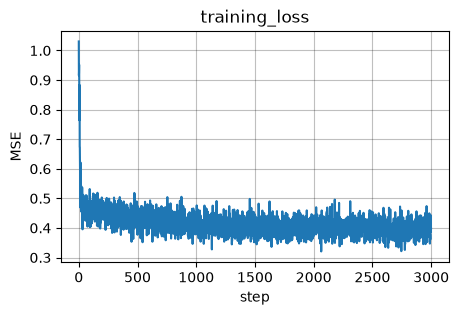

In [20]:
optimizer = torch.optim.AdamW(params=model.parameters(), lr=2e-3)
loss_history = []

for step in range(3000):
    optimizer.zero_grad()
    loss = training_step(model, x0_dataset=x0, batch_size=512)
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())
    if step % 500 == 0:
        print(f"step {step:4d} | loss {loss.item():.4f}")

plt.figure(figsize=(5, 3))
plt.plot(loss_history)
plt.title("training_loss")
plt.xlabel("step")
plt.ylabel("MSE")
plt.grid(True, color=(0.0, 0.0, 0.0, 0.25))
plt.show()

### 7.1 学習した重みを保存する

学習が終わった直後に、モデルの学習済みパラメータだけを `denoise_mlp_weights.pth` へ保存してください。

### 直後のコードセルで実装すること

1. 保存先を `weights_path = "denoise_mlp_weights.pth"` とする
2. `model.state_dict()` で各層の重みとバイアスを取り出す
3. `torch.save` で保存する

ここではクラス定義、`T`、ノイズスケジュール、最適化器は保存しません。読み込み時には、同じ `DenoiseMLP(time_dim=32, hidden_dim=128)` をもう一度作ります。


In [21]:
weights_path = "denoise_mlp_weights.pth"
torch.save(model.state_dict(), weights_path)
print(f"saved: {weights_path}")

saved: denoise_mlp_weights.pth


## 8. 逆過程でサンプリング

保存した学習済みモデルを読み込み、標準正規ノイズから三日月データへ戻します。

DDPM の基本形では、逆方向の平均は次で計算できます。

$$
\mu_\theta(x_t, t) =
\frac{1}{\sqrt{1 - \beta_t}}
\left(
  x_t - \frac{\beta_t}{\sqrt{1 - \prod_{s=1}^{t}(1 - \beta_s)}}\epsilon_\theta(x_t, t)
\right)
$$

`t > 0` ではノイズを足し、`t = 0` では平均をそのまま使います。


### 8.1 保存した重みを読み込む

### 直後のコードセルで実装すること

1. 学習時と同じ `DenoiseMLP(time_dim=32, hidden_dim=128)` を作り、`.to(device)` で実行環境へ移す
2. `torch.load(weights_path, map_location=device, weights_only=True)` で重みを読む
3. `model.load_state_dict(...)` で読み込んだ重みをモデルへ設定する
4. `model.eval()` で推論モードへ切り替える

`map_location=device` は、重みを現在のCPU/GPUへ配置する指定です。モデル構造が保存時と違う場合は `load_state_dict` がエラーになるため、`time_dim` と `hidden_dim` を保存時に合わせてください。


In [22]:
weights_path = "denoise_mlp_weights.pth"
model = DenoiseMLP(time_dim=32, hidden_dim=128).to(device)
state_dict = torch.load(weights_path, map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.eval()
print(f"loaded: {weights_path}")

loaded: denoise_mlp_weights.pth


### 8.2 `p_sample`

この直後のセルでは `p_sample` だけを書きます。

- 役割: 現在の `x_t` から、一つ前の時刻のサンプル（三日月の点）を1回作る
- 入力: `model`, `x`, `t`
- 出力shape: `x`と同じ
- 使用する関数: `extract_timestep_values`, `torch.sqrt`, `torch.randn_like`

#### 逆拡散なのに、なぜ新しいノイズを加えるのか

順拡散の1ステップは、次の式で `x_{t-1}` にノイズを加えて `x_t` を作ります。

$$
x_t=\sqrt{1-\beta_t}\,x_{t-1}+\sqrt{\beta_t}\,\epsilon_t
$$

逆方向では `x_t` だけが分かっていますが、元の `x_{t-1}` と、そのとき使われた $\epsilon_t$ は両方とも分かりません。同じ `x_t` を作り得る `x_{t-1}` とノイズの組み合わせは複数あるため、`x_t` から元の `x_{t-1}` を一意に逆算できません。

`p_sample` は、順拡散で実際に通った状態を正確に復元する関数ではありません。モデルが計算した `mean` へ移動して大きくノイズを減らした後、まだ残っている「一つ前の状態がどれだったか」という不確実性の範囲から、候補を一つ選びます。その候補選びに使う乱数が `reverse_epsilon` です。

したがって、`reverse_epsilon` はデータをもう一度壊すためのノイズではなく、**一意に決まらない `x_{t-1}` の候補から一つをサンプリングするための乱数**です。

#### `mean` は何の平均か

現在の `x_t` を固定しても、一つ前の状態 `x_{t-1}` は一つには決まりません。新しく加えるノイズを変えると、同じ `x_t` から少しずつ異なる `x_{t-1}` が得られます。`mean` は、そうして得られる候補全体の中心です。

$$
\text{mean}=\mathbb E[x_{t-1}\mid x_t]
$$

この平均を考えるときは、次のように区別します。

- 固定するもの: 現在の `x_t`、時刻 `t`、学習済みモデル
- 変えるもの: 新しく生成する `reverse_epsilon`
- 平均するもの: 異なる `reverse_epsilon` から得られる複数の `x_{t-1}`

これは1000点のバッチを一つの値へ平均する処理ではありません。各点について次の候補の中心を計算するため、`x.shape=[batch, 2]` なら `mean.shape=[batch, 2]` です。各行には、その点に対応する平均の2座標が入ります。

#### `reverse_epsilon = torch.randn_like(x)` は何を作るのか

`reverse_epsilon` は、逆拡散で一つ前の状態をランダムに選ぶために、**その場で新しく作る標準正規ノイズ**です。

- `pred_epsilon`: モデルが、現在の `x_t` に含まれていると予測したノイズ
- `reverse_epsilon`: 計算した平均の周りから `x_{t-1}` をサンプリングするために、新しく加えるノイズ

`torch.randn_like(x)` は、`x` と同じshape・dtype・deviceを持ち、各要素が独立に $\mathcal N(0,1)$ から選ばれたTensorを作ります。今回 `x.shape=[batch, 2]` なら、`reverse_epsilon.shape=[batch, 2]` です。各点の2座標に同じ値を使うのではなく、点ごと・座標ごとに別の乱数が入ります。

この関数の最後では、次の形で平均へ揺らぎを加えます。

$$
x_{t-1}=\text{mean}+\text{nonzero\_mask}\sqrt{\beta_t}\,\text{reverse\_epsilon}
$$

`t=0` でも `reverse_epsilon` 自体は生成されますが、`nonzero_mask` が0になるため、完成した点へこのノイズは加わりません。

この関数が呼ばれるとき、バッチ内の全サンプル（三日月の点）は同じ現在時刻を持ちます。例えば `t=[50, 50, ..., 50]` です。時刻を逆順に進めるループは、このセルでは扱いません。


In [23]:
@torch.no_grad()
def p_sample(model, x, t):
    beta_t = extract_timestep_values(beta, t).expand_as(x)
    beta_keep_t = extract_timestep_values(beta_keep, t).expand_as(x)

    pred_epsilon = model(x, t)
    mean = (1.0 / torch.sqrt(1.0 - beta_t)) * (x - beta_t / torch.sqrt(1.0 - beta_keep_t) * pred_epsilon) 

    reverse_epsilon = torch.randn_like(x) # nは正規分布のn
    nonzero_mask = (t != 0).float().unsqueeze(1).expand_as(x)
    return mean + nonzero_mask * torch.sqrt(beta_t) * reverse_epsilon



### 8.3 `sample`

このセルではこの関数だけを書きます。標準正規ノイズから開始し、`p_sample` を `T-1` から0まで繰り返して、1000点を生成します。

この関数では、各逆拡散ステップでバッチ内の全サンプル（三日月の点）を同じ時刻にし、`T-1, T-2, ..., 0` の順に進めます。


In [24]:
@torch.no_grad()
def sample(model, n_samples=1000):
    x = torch.randn(n_samples, 2, device=device)
    snapshots = {}

    for i in reversed(range(T)): # T-1, T-2, ..., 0の順
        t = torch.full(size=(n_samples, ), fill_value=i, device=device, dtype=torch.long)
        x = p_sample(model, x, t)
        if i in [99, 74, 49, 24, 0]:
            snapshots[i] = x.detach().clone()

    return x, snapshots


### 8.4 生成と表示

関数は定義しません。`sample` を呼び、1000点の途中の点群を `plot_points` で表示します。


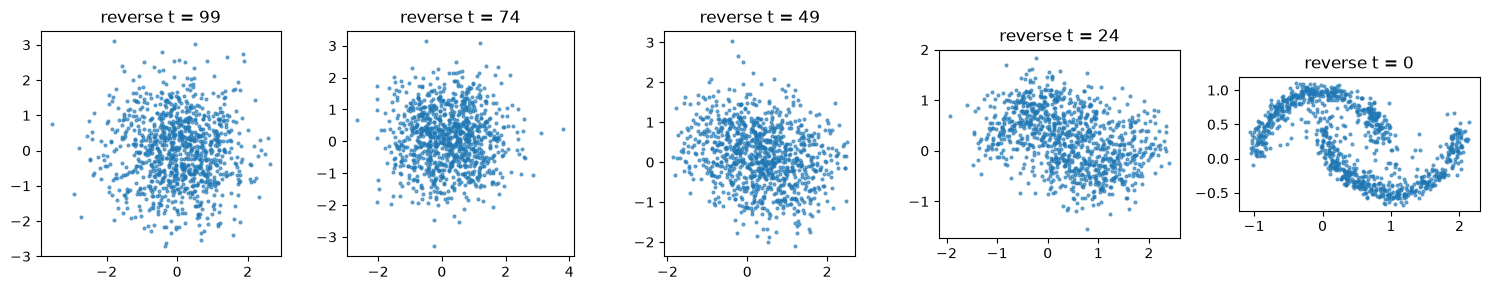

In [26]:
samples, snapshots = sample(model)

fig, axes = plt.subplots(nrows=1,ncols=5, figsize=(15, 3))
for ax, t_value in zip(axes, [99, 74, 49, 24, 0]):
    plot_points(snapshots[t_value], title=f"reverse t = {t_value}", ax=ax, s=4, opacity=0.6)
plt.tight_layout()


## 9. 答え合わせ用チェック

自分で実装した処理を確認するテストを、空のコードセルに書いてください。正解例は `diffusion1.ipynb` にあります。

### 直後のコードセルで行うこと

このセルは新しい機能を実装する問題ではなく、ここまでの実装を機械的に確認するテストです。

- `beta_keep` のshapeと値の範囲が正しいか
- `q_sample` の出力shapeが入力と一致するか
- 実際のノイズのshapeが入力と一致するか
- `training_step` が有限なスカラー損失を返すか

失敗した場合は、表示された `assert` の直前にある変数のshapeや値を確認します。

### このセルで使う主な関数名

- 条件を検証する: Pythonの `assert`
- Tensor内の全条件をまとめる: `torch.all`
- 有限値か確認する: `torch.isfinite`
- テスト用の時刻を作る: `torch.randint`
- shapeを確認する: `Tensor.shape`, `Tensor.ndim`


In [27]:
assert beta_keep.shape == (T,)
assert torch.all(beta_keep > 0)
assert beta_keep[0] > beta_keep[-1]

x_check = x0[:8]
t_check = torch.randint(0, T, (8,), device=device)
xt_check, epsilon_check = q_sample(x_check, t_check, beta_keep)
assert xt_check.shape == x_check.shape
assert epsilon_check.shape == x_check.shape

loss_check = training_step(model, x0, batch_size=8)
assert loss_check.ndim == 0
assert torch.isfinite(loss_check)

print("OK: Q1-Q8 の基本チェックを通過しました")


OK: Q1-Q8 の基本チェックを通過しました
